# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [1]:
import pandas as pd 
import seaborn as sns # importar librerías
import matplotlib.pyplot as plt

In [2]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv("/datasets/users_latam.csv")#completa el código
usage = pd.read_csv("/datasets/usage.csv") #completa el código

In [3]:
plans.head()# mostrar las primeras 5 filas de plans

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
users.head()# mostrar las primeras 5 filas de users

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
usage.head()# mostrar las primeras 5 filas de usage

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [6]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [7]:
plans.info()# inspección de plans con .info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [8]:
users.info()# inspección de users con .info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [9]:
usage.info()# inspección de usage con .info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [10]:

# cantidad de nulos para users
nulos_users = pd.DataFrame({
    "nulos": users.isna().sum(),
    "% nulos": (users.isna().mean() * 100).round(2)
})
nulos_users.sort_values("% nulos", ascending=False)


,nulos,% nulos
churn_date,3534,88.35
city,469,11.72
user_id,0,0.00
first_name,0,0.00
last_name,0,0.00
age,0,0.00
reg_date,0,0.00
plan,0,0.00


In [11]:
# cantidad de nulos para usage
nulos_usage = pd.DataFrame({
    "nulos": usage.isna().sum(),
    "% nulos": (usage.isna().mean() * 100).round(2)
})
nulos_usage.sort_values("% nulos", ascending=False)

,nulos,% nulos
duration,22076,55.19
length,17896,44.74
date,50,0.12
id,0,0.00
user_id,0,0.00
type,0,0.00


In [12]:
users["city"].value_counts(dropna=False)

Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64

✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?  
- Indica qué harías: ¿imputar, eliminar, ignorar?
- 
**nulos en users**
 Se identifican 96 valores "?" en la columna city.
 Aunque no son reconocidos por .isna(), representan ausencia de información.
 Se reemplazan por NaN para unificar el tratamiento de valores faltantes.
 La proporción total de nulos permanece por debajo del 30%, por lo que se conserva la columna.
 churn_date tiene 466 no nulos: solo 466 usuarios se dieron de baja y los otros 3534 siguen activos. Aquí el NaN es normal.
 
 **nulos en usage**
 Los nulos en 'duration' y 'length' son esperados y no representan datos faltantes.
 Cada fila corresponde a una llamada o a un mensaje de texto, por lo que solo una
 de las dos columnas contiene información. No se realizará ningún tratamiento sobre estos nulos.
 La columna 'date' presenta 39.950 registros no nulos, lo que indica la existencia
 de 50 fechas faltantes. Dado que la proporción de valores ausentes es inferior al 5%
 del total de observaciones, estos registros serán tratados como valores nulos durante
 el proceso de limpieza de datos, ya que su impacto sobre el análisis es mínimo.
 

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [13]:
 print(users["user_id"].describe())# explorar columnas numéricas de users
 print(users["age"].describe())

count     4000.000000
mean     11999.500000
std       1154.844867
min      10000.000000
25%      10999.750000
50%      11999.500000
75%      12999.250000
max      13999.000000
Name: user_id, dtype: float64
count    4000.000000
mean       33.739750
std       123.232257
min      -999.000000
25%        32.000000
50%        47.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64


- La columna `user_id`es una variable identificadora, no una medida numérica. Por ello, estadísticas como media o máximo carecen de valor     analítico.
- La columna `age` Se identifica un valor mínimo de -999, el cual no es válido para una edad.
- Como parte de la limpieza de datos, los registros con edad = -999 serán reemplazados por la mediana  para su posterior tratamiento como correccion de sentinels.

In [14]:

print(usage["id"].describe()) # explorar columnas numéricas de usage
print(usage["user_id"].describe())   


count    40000.00000
mean     20000.50000
std      11547.14972
min          1.00000
25%      10000.75000
50%      20000.50000
75%      30000.25000
max      40000.00000
Name: id, dtype: float64
count    40000.000000
mean     12002.405975
std       1157.279564
min      10000.000000
25%      10996.000000
50%      12013.000000
75%      13005.000000
max      13999.000000
Name: user_id, dtype: float64


- Las columna `id` funciona como un identificador secuencial de los registros.
 Presenta 40.000 valores únicos distribuidos consecutivamente entre 1 y 40.000.
- Las columna `user_id` Se identifican aproximadamente 4.000 IDs la diferencia entre min y max
- cantidad que coincide con el número total de usuarios registrados en la  tabla 'users'. Esto sugiere una correspondencia consistente entre ambas fuentes de datos y constituye un indicador positivo de integridad referencial.

In [15]:


# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
for col in columnas_user:
    print(col.upper().center(40, "*"))
    print(users[col].value_counts(dropna=False))
    print()



******************CITY******************
Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64

******************PLAN******************
Basico     2595
Premium    1405
Name: plan, dtype: int64



- La columna `city` Se identifican 6 ciudades válidas, incluyendo las siglas CDMX, GDL y MTY. Asimismo, se detectan 469 valores nulos y 96 registros con el valor '?',serán reemplazados por NaN  para unificar el tratamiento de los datos faltantes.

- La columna `plan` La variable contiene únicamente dos categorías: 'Basico' (2.595 registros)  y 'Premium' (1.405 registros). La suma de ambas coincide con el total de usuarios (4.000 registros), por lo que no se identifican valores nulos.

In [16]:
# explorar columna categórica de usage
usage['type'].value_counts(dropna=False) # completa el código

text    22092
call    17908
Name: type, dtype: int64

- La columna `type` La variable contiene únicamente dos categorías válidas: 'text' (22.092 registros) y 'call' (17.908 registros). La suma de ambas categorías coincide con el total de observaciones (40.000 registros), por lo que no se identifican valores nulos


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?  
- ¿Qué acción tomarías?

  **`users["age"]`:** contiene el valor `-999`.Es un valor centinela de "edad desconocida": una edad negativa es imposible y distorsiona
  el promedio (33.74 frente a una mediana de 47) y la desviación estándar (123.23).
  **Acción:** reemplazar `-999` imputaraia con la mediana  para que no afecte las estadísticas. No eliminaría las filas, porque el resto de la   información del usuario sigue siendo útil.

  **`users["city"]`:** contiene `?` en 96 registros, un faltante disfrazado de texto que `isna()` no detecta. Sumado a los 469 nulos reales,   
son 565 faltantes (14.13 %) y no 11.72 %.

  **Acción:** reemplazar `?` por nulo real. la dejaría como nula o la categorizaría como "Desconocida".

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [17]:
  # analis de nulos antes de converir a fortamo fecha 
columnas_fecha = [(users, "reg_date"), (users, "churn_date"), (usage, "date")]

for df, col in columnas_fecha:  #para el for trabajo con una tupla ya que las  fechas viven en dos tablas distintas, así que cada columna debe ir acompañada de su tabla.
    nulos_antes = df[col].isna().sum()
    convertida = pd.to_datetime(df[col], errors="coerce")
    nulos_despues = convertida.isna().sum()
    print(f"{col}: nulos antes = {nulos_antes}, después = {nulos_despues}, "
          f"no convertibles = {nulos_despues - nulos_antes}")

reg_date: nulos antes = 0, después = 0, no convertibles = 0
churn_date: nulos antes = 3534, después = 4000, no convertibles = 466
date: nulos antes = 50, después = 50, no convertibles = 0


In [18]:
# Convertir a fecha la columna `reg_date` de users
users["reg_date"]=pd.to_datetime(users["reg_date"],errors="coerce")

In [19]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage["date"],errors="coerce")# completa el código

In [20]:
# Revisar los años presentes en `reg_date` de users
print(users["reg_date"].dtype)
print(users["reg_date"].dt.year.value_counts(dropna=False).sort_index())

datetime64[ns]
2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64


In [21]:
print(users.loc[users["reg_date"].dt.year > 2024, "reg_date"].value_counts())

2026-05-10    40
Name: reg_date, dtype: int64


In [22]:
ids_futuros = users.loc[users["reg_date"].dt.year > 2024, "user_id"]
print(usage["user_id"].isin(ids_futuros).sum())

374


En `reg_date`,se convirtió correctamente a formato fecha. Se identificaron 40 registros (1 %) con la fecha 2026-05-10, valor fuera del rango esperado, ya que el conjunto de datos contiene información hasta 2024. Al validar estos usuarios en la tabla usage, se encontraron 374 registros de uso, lo que confirma que son usuarios reales y activos. Por tanto, la inconsistencia corresponde a un error en la fecha de registro y no a usuarios inválidos que deban ser eliminados

In [23]:

    # Revisar los años presentes en `date` de usage
    print(usage["date"].dtype)
    print(usage["date"].dt.year.value_counts(dropna=False).sort_index())


datetime64[ns]
2024.0    39950
NaN          50
Name: date, dtype: int64


En `date`,La conversión a datetime64[ns] fue exitosa. Los 39.950 registros válidos corresponden a 2024 y los 50 valores nulos coinciden con los identificados previamente, sin pérdida de filas durante la transformación.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- ¿Qué harías con ellas?

**Fechas imposibles en `users["reg_date"]`**

Los datos disponibles llegan hasta el año 2024. Al revisar los años de `reg_date`
se encontraron 40 registros (1 % de los 4000 usuarios) con fecha en 2026; en todos
la fecha es idéntica (`2026-05-10`), lo que sugiere un valor por defecto o
centinela y no un error de captura aleatorio.

Se verificó que estos 40 usuarios son reales: tienen 374 registros de uso en la
tabla `usage` (≈ 9 por usuario, similar al promedio general). Por eso no se
eliminarán las filas, ya que se perdería información válida del resto de las
columnas y de su consumo.

**Acción:** reemplazar `reg_date` por `NaT` (fecha nula) en esos 40 registros y
conservar el resto de la información del usuario.


---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [24]:

# Reemplazar -999 por la mediana de age

n_antes = (users["age"] == -999).sum()
mediana_age = users.loc[users["age"] != -999, "age"].median()
print(n_antes, mediana_age)

users.loc[users["age"] == -999, "age"] = mediana_age

print((users["age"] == -999).sum())  # debe dar 0
# Verificar cambios
print(users["age"].describe())


55 48.0
0
count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64


In [25]:
# Reemplazar ? por NA en city
print((users["city"] == "?").sum())  # 96

users["city"] = users["city"].replace("?", pd.NA)

print((users["city"] == "?").sum())  # 0
# Verificar cambios
print(users["city"].isna().sum())    # debe dar 469 + 96 = 565


96
0
565


In [26]:

    # Marcar fechas futuras como NA para reg_date
    mascara = users["reg_date"].dt.year > 2024
    print(mascara.sum())  # 40
    
    users.loc[mascara, "reg_date"] = pd.NaT
    
    # Verificar cambios
    print(users["reg_date"].isna().sum())       # debe dar 40
    print(users["reg_date"].dt.year.value_counts(dropna=False).sort_index())



40
40
2022.0    1314
2023.0    1316
2024.0    1330
NaN         40
Name: reg_date, dtype: int64


### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [27]:
# Verificación MAR en usage (Missing At Random) para duration
for col in ["duration", "length"]:
    print(f"{col.upper()} es nulo".center(40, "*"))
    print(pd.crosstab(usage["type"], usage[col].isna()))
    print()

************DURATION es nulo************
duration  False  True 
type                  
call      17908      0
text         16  22076

*************LENGTH es nulo*************
length  False  True 
type                
call       12  17896
text    22092      0



In [28]:
# Verificación MAR en usage (Missing At Random) para length
for col in ["duration", "length"]:
    print(f"% nulos de {col} por tipo".center(40, "*"))
    print((usage.groupby("type")[col].apply(lambda s: s.isna().mean()) * 100).round(2))
    print()

******% nulos de duration por tipo******
type
call     0.00
text    99.93
Name: duration, dtype: float64

*******% nulos de length por tipo*******
type
call    99.93
text     0.00
Name: length, dtype: float64



Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length` Al analizar los valores faltantes en conjunto con la variable type, se observa que duration presenta valores nulos en el 99,93 % de los registros de texto y en el 0 % de las llamadas. De manera análoga, length es nulo en el 99,93 % de las llamadas y en el 0 % de los mensajes de texto. Este patrón indica que la ausencia de datos no es completamente aleatoria, sino que depende del tipo de evento registrado, por lo que puede clasificarse como un caso de datos faltantes estructurales (MAR). se dejan como nulos

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [29]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = usage.groupby("user_id").agg(
    cant_mensajes=("is_text", "sum"),
    cant_llamadas=("is_call", "sum"),
    cant_minutos_llamada=("duration", "sum")
).reset_index() 
# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [30]:
print(usage_agg.columns.tolist())
print(usage_agg[["cant_mensajes", "cant_llamadas"]].sum())  # suma total: 40000
print(usage_agg["user_id"].is_unique)  # True


['user_id', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
cant_mensajes    22092
cant_llamadas    17908
dtype: int64
True


In [31]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on="user_id", how="left")

# Rellenar con 0 a los usuarios sin eventos de uso
cols_uso = ["cant_mensajes", "cant_llamadas", "cant_minutos_llamada"]
user_profile[cols_uso] = user_profile[cols_uso].fillna(0)

# Validaciones
print(len(user_profile))                    # debe ser 4000
print(user_profile[cols_uso].isna().sum())  # debe dar 0 en las tres

user_profile.head(5)

4000
cant_mensajes           0
cant_llamadas           0
cant_minutos_llamada    0
dtype: int64


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [32]:

# Resumen estadístico de las columnas numéricas
cols_num = ["age", "cant_mensajes", "cant_llamadas", "cant_minutos_llamada"]
user_profile[cols_num].describe()


,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,4000.000000,4000.000000
mean,48.136000,5.523000,4.477000,23.311225
std,17.689919,2.359738,2.145139,18.169564
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.107500
50%,48.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.412500
max,79.000000,17.000000,15.000000,155.690000


In [33]:

# Distribución porcentual del tipo de plan
pd.DataFrame({
    "usuarios": user_profile["plan"].value_counts(),
    "% usuarios": (user_profile["plan"].value_counts(normalize=True) * 100).round(2)
})


,usuarios,% usuarios
Basico,2595,64.88
Premium,1405,35.12


---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

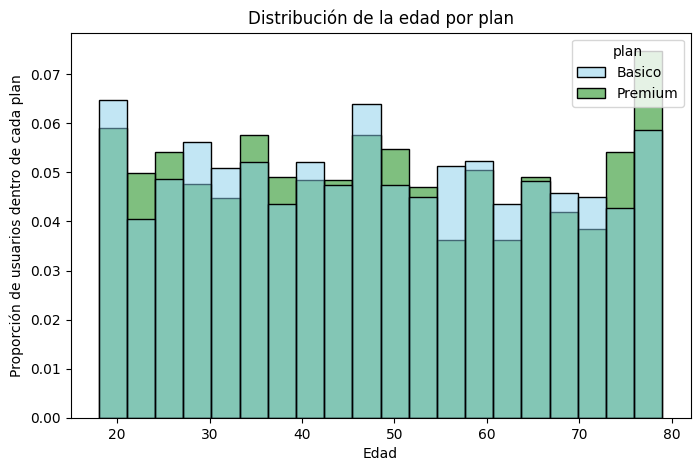

In [34]:
# Histograma para visualizar la edad (age)
plt.figure(figsize=(8, 5))
sns.histplot(data=user_profile, x="age", hue="plan",
             palette=["skyblue", "green"], bins=20,
              stat="probability", common_norm=False),
plt.title("Distribución de la edad por plan")
plt.xlabel("Edad")
plt.ylabel("Proporción de usuarios dentro de cada plan")
plt.show()

💡Insights: 
- La edad de los usuarios se distribuye de forma aproximadamente uniforme entre 18 y 79 años, con entre 4 % y 6 % de los usuarios en cada intervalo y sin sesgo hacia ningún lado. Al comparar en porcentajes dentro de cada plan, Basico y Premium tienen distribuciones muy parecidas, por lo que no se observa un patrón claro entre la edad y el plan.


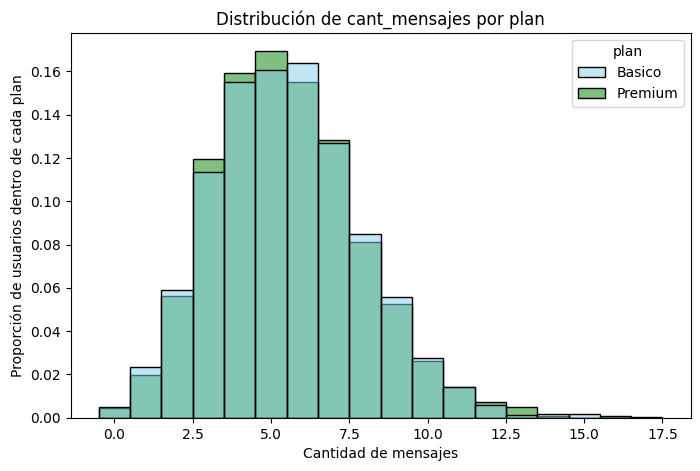

In [35]:


# Histograma para visualizar cant_mensajes
plt.figure(figsize=(8, 5))
sns.histplot(data=user_profile, x="cant_mensajes", hue="plan",
             palette=["skyblue", "green"], discrete=True,
             stat="probability", common_norm=False),
plt.title("Distribución de cant_mensajes por plan")
plt.xlabel("Cantidad de mensajes")
plt.ylabel("Proporción de usuarios dentro de cada plan")
plt.show()


        



💡Insights: 
La cantidad de mensajes tiene una distribución sesgada a la derecha, con la mayoría de los usuarios entre 4 y 6 mensajes y una cola corta hasta 17. Basico tiene más usuarios en términos absolutos (64.88 % frente a 35.12 %), por lo que la comparación se hizo en proporciones dentro de cada plan. Ambos planes muestran la misma forma y el mismo pico, por lo que no se observa un patrón claro entre el plan y la cantidad de mensajes.



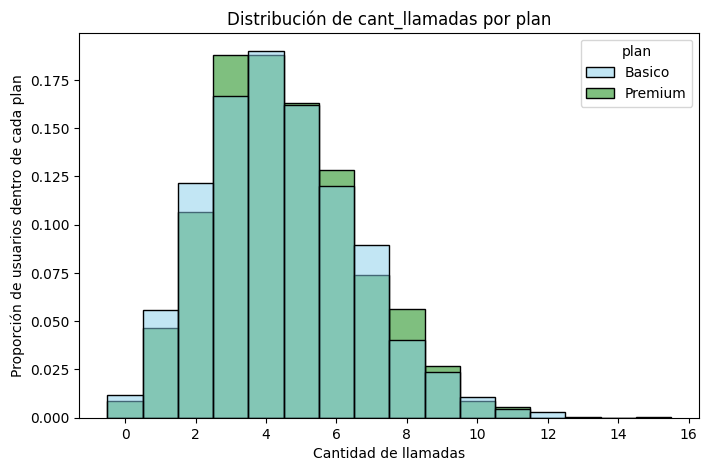

In [36]:

# Histograma para visualizar la cant_llamadas
plt.figure(figsize=(8, 5))
sns.histplot(data=user_profile, x="cant_llamadas", hue="plan",
             palette=["skyblue", "green"], discrete=True,
             stat="probability", common_norm=False)
plt.title("Distribución de cant_llamadas por plan")
plt.xlabel("Cantidad de llamadas")
plt.ylabel("Proporción de usuarios dentro de cada plan")
plt.show()


💡Insights: 
- La cantidad de llamadas tiene una distribución sesgada a la derecha, con la mayoría de los usuarios entre 3 y 5 llamadas y una cola corta hasta 15. Al comparar en proporciones dentro de cada plan, Basico y Premium muestran formas y picos casi idénticos, por lo que no se observa un patrón claro entre el plan y la cantidad de llamadas.

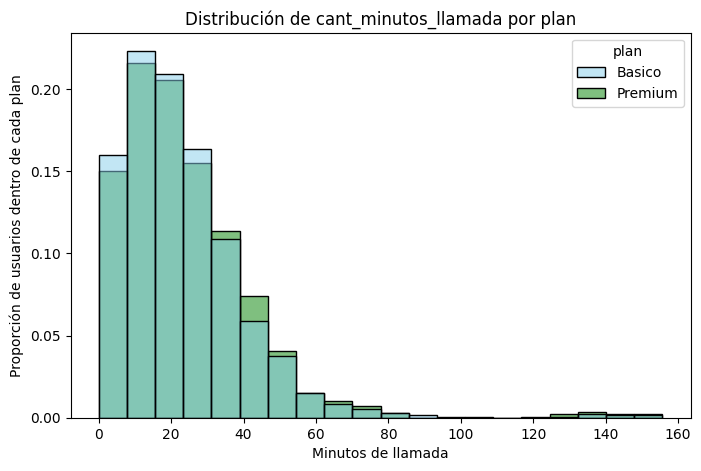

In [37]:


# Histograma para visualizar la cant_minutos_llamada
plt.figure(figsize=(8, 5))
sns.histplot(data=user_profile, x="cant_minutos_llamada", hue="plan",
             palette=["skyblue", "green"], bins=20,
             stat="probability", common_norm=False)
plt.title("Distribución de cant_minutos_llamada por plan")
plt.xlabel("Minutos de llamada")
plt.ylabel("Proporción de usuarios dentro de cada plan")
plt.show()



💡Insights: 
- Los minutos de llamada tienen una distribución fuertemente sesgada a la derecha: la mayoría de los usuarios acumula entre 8 y 30 minutos y un grupo pequeño (31 usuarios, 0.78 %) supera los 100 minutos, con un máximo cercano a 155. Basico y Premium son muy parecidos (medias de 22.9 y 24.1, medianas de 19.5 y 20.6). Entre los usuarios con más de 100 minutos, el 45 % es Premium frente al 35 % que representa en la base, una ligera sobrerrepresentación que, con tan pocos casos, no permite afirmar un patrón firme. Estos usuarios no hacen más llamadas, sino llamadas mucho más largas.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

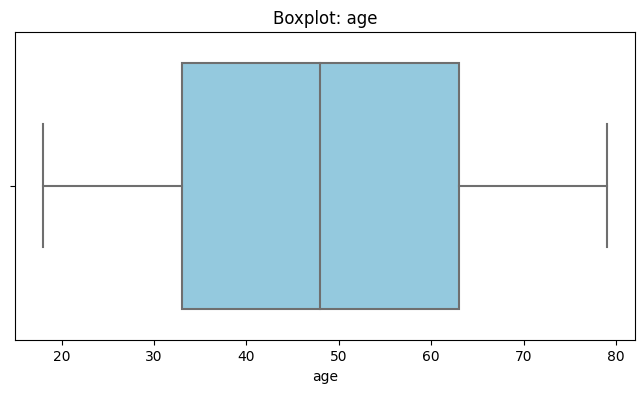

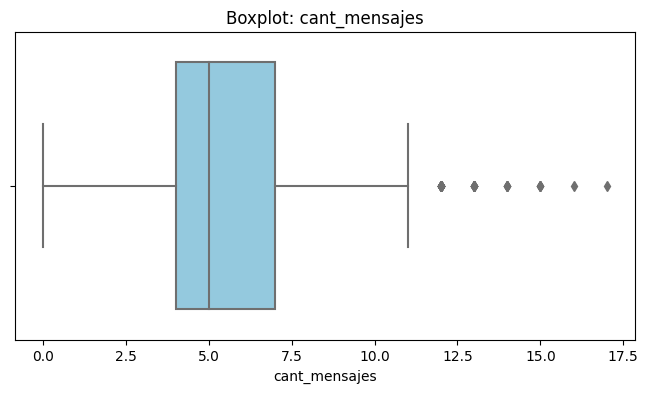

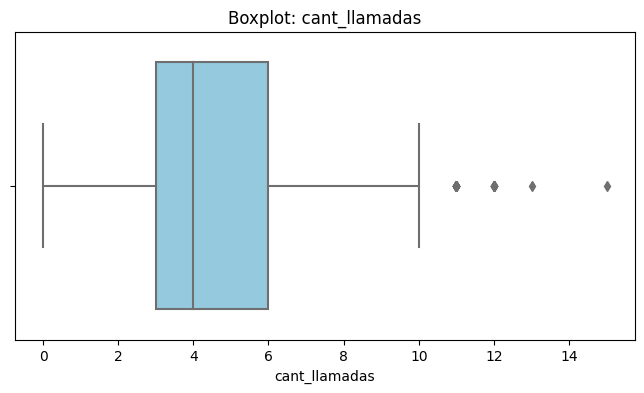

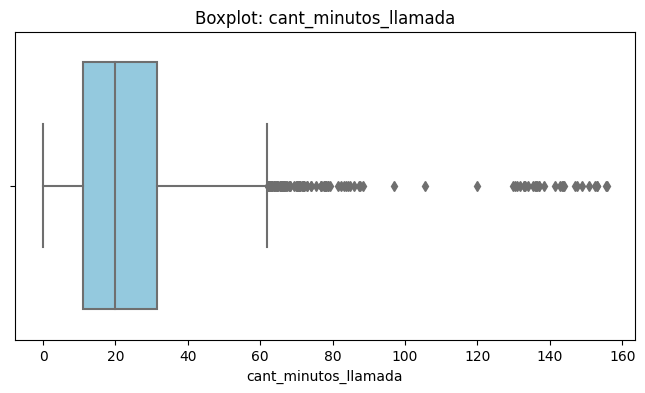

In [38]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    plt.figure(figsize=(8, 4))
    sns.boxplot(data=user_profile, x=col, color="skyblue")
    plt.title(f"Boxplot: {col}")
    plt.xlabel(col)
    plt.show()

💡Insights: 
- Age: no presenta valores outliers 
- cant_mensajes: presenta outliers con distribucion sesgada a la derecha  
- cant_llamadas: presenta outliers con distribucion sesgada a la derecha
- cant_minutos_llamada:presenta outliers con distribucion sesgada a la derecha

In [39]:

# Calcular límites con el método IQR
columnas_limites = ["cant_mensajes", "cant_llamadas", "cant_minutos_llamada"]

for col in columnas_limites:
    q1 = user_profile[col].quantile(0.25)
    q3 = user_profile[col].quantile(0.75)
    iqr = q3 - q1
    limite_sup = q3 + 1.5 * iqr
    n_out = (user_profile[col] > limite_sup).sum()
    print(f"{col}: límite superior={limite_sup:.2f}, "
          f"outliers={n_out} ({n_out/len(user_profile)*100:.2f} %)")



cant_mensajes: límite superior=11.50, outliers=46 (1.15 %)
cant_llamadas: límite superior=10.50, outliers=30 (0.75 %)
cant_minutos_llamada: límite superior=61.87, outliers=109 (2.73 %)


In [40]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,4000.000000
mean,5.523000,4.477000,23.311225
std,2.359738,2.145139,18.169564
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.107500
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.412500
max,17.000000,15.000000,155.690000




💡 Insights

 cant_mensajes:  Se mantienen los valores atípicos, ya que el máximo observado (17)  se encuentra relativamente cerca del límite superior estimado (11.5).  Además, representan pocos casos y su impacto sobre la media es mínimo,  por lo que no justifican una transformación o tratamiento adicional.

 cant_llamadas:  Al igual que en la variable de mensajes, se conservan los valores atípicos.  El valor máximo está próximo al límite superior (10.5) y corresponde a  una pequeña proporción de registros, con escasa influencia sobre las  medidas de tendencia central.

 cant_minutos_llamada:  Se aplicará winsorización debido a la presencia de una cola derecha  pronunciada. El valor máximo se encuentra muy por encima del límite  superior esperado, generando una distorsión importante en la distribución.  Esto se refleja en una media (23.3) superior a la mediana (19.8), señal  de asimetría causada por valores extremos.


---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [41]:


import numpy as np

condiciones = [
    (user_profile["cant_llamadas"] < 5) & (user_profile["cant_mensajes"] < 5),
    (user_profile["cant_llamadas"] < 10) & (user_profile["cant_mensajes"] < 10),
]
etiquetas = ["Bajo uso", "Uso medio"]

user_profile["grupo_uso"] = np.select(condiciones, etiquetas, default="Alto uso")

In [42]:

# verificar cambios
user_profile.head()


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso



6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos


In [43]:
# Crear columna grupo_edad

condiciones_edad = [
    user_profile["age"] < 30,
    user_profile["age"] < 60,
]
etiquetas_edad = ["Joven", "Adulto"]

user_profile["grupo_edad"] = np.select(condiciones_edad, etiquetas_edad, default="Adulto Mayor")

In [44]:

# verificar cambios
user_profile.head()


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

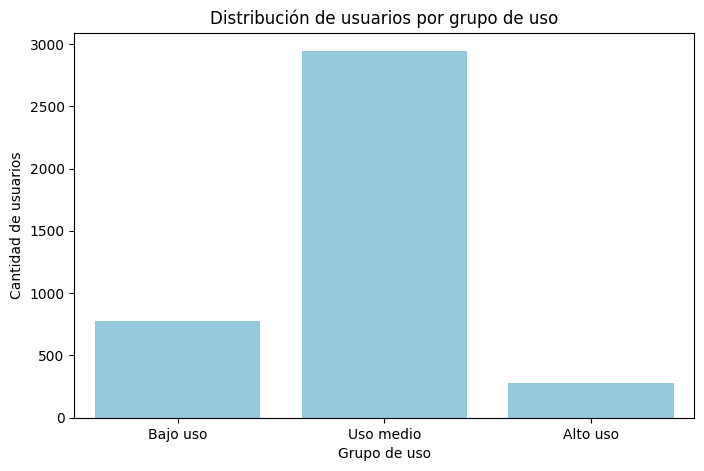

In [45]:

# Visualización de los segmentos por uso
plt.figure(figsize=(8, 5))
sns.countplot(data=user_profile, x="grupo_uso",
              order=["Bajo uso", "Uso medio", "Alto uso"],
              color="skyblue")
plt.title("Distribución de usuarios por grupo de uso")
plt.xlabel("Grupo de uso")
plt.ylabel("Cantidad de usuarios")
plt.show()


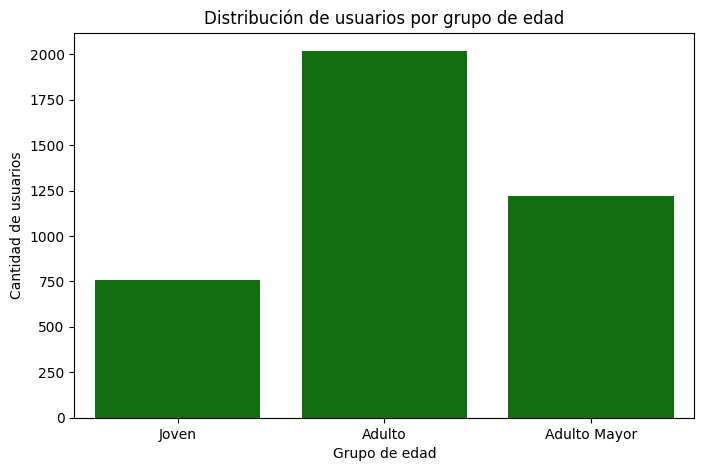

In [47]:

# Visualización de los segmentos por edad
plt.figure(figsize=(8, 5))
sns.countplot(data=user_profile, x="grupo_edad",
              order=["Joven", "Adulto", "Adulto Mayor"],
              color="green")
plt.title("Distribución de usuarios por grupo de edad")
plt.xlabel("Grupo de edad")
plt.ylabel("Cantidad de usuarios")
plt.show()



---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
- columna users.age valor centinela -999 (edad desconocida) 55 filas  se imputaron con la mediana (48)
- 
- columna users.city  faltantes: 469 nulos + 96 con "?"  565 de 4000 (14.13 %) , "?" convertido a nulo 
- columna users.reg_date  Fecha imposible 2026-05-10 (datos llegan a 2024) filas 40 (1 %)  Convertida a nulo; los usuarios son reales (374 registros de uso) 
- columna usage.date  Fechas faltantes  50 de 40 000 (0.13 %)  Se dejan como nulos 
- columna usage (type, duration, length)  Valor en la columna que no corresponde al tipo 28 filas (0.07 %)  Documentadas 
- columna Fechas  Estaban como texto  filas 3, columnas  Convertidas a fecha
- Los nulos de duration y length no son error: un mensaje no tiene duración ni una llamada tiene longitud. Un usuario no tiene ningún evento de uso (se registró con 0)

🔍 **Segmentos por Edad**
-  Adulto (30-59) 50.45%
-  Adulto Mayor (>60) 30.55%
-  Joven (<30) 19.00%

📊 **Segmentos por Nivel de Uso**
- llamadas y mensajes:
- Uso medio 73.58%
- Bajo uso 19.48%
- Alto uso 6.95%

➡️ Esto sugiere que ...
El nivel de uso es casi igual en todas las edades (Uso medio entre 72.6% y 74.3%; Alto uso entre 6.1% y 7.6%).
Los adultos usan ligeramente más, pero la diferencia es pequeña , tienen una proporción algo mayor de Alto uso (7.58%)
Tampoco hay diferencias claras entre Basico y Premium tienen un uso de llamadas casi idéntico, con medianas de 19.5 y 20.6 minutos
Por edad: el nivel de uso es prácticamente igual en los tres grupos  Los adultos ), pero la diferencia es pequeña.



💡 **Recomendaciones**
- si se quiere diseñar ofertas, no sirve segmentar por edad ni asumir que Premium usa más. Conviene segmentar por comportamiento real por ejemplo, los usuarios de Alto uso o los de llamadas muy largas.
- Plan de entrada más económico para el 19.5 % de Bajo uso menos de 5 llamadas y 5 mensajes
- Oferta para llamadas largas (paquete de minutos o plan específico) para el grupo de más de 100 minutos, y revisar si los Basico con alto consumo exceden los minutos incluidos y convienen a Premium

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`